# 0. Load

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import KNNImputer
import os
import json

In [2]:
df = pd.read_csv("../Data/churn_processed.csv")
df = df[df['Churn'] == 1]
df = df.drop(columns = ["CustomerID", "Churn"])
df_churn = df.copy()

# 1. Preprocessing

## a. Encode

In [3]:
df_churn['CouponUsed'] = df_churn['CouponUsed'].fillna(0)
df_churn['OrderCount'] = df_churn['OrderCount'].fillna(0)
df_churn['DaySinceLastOrder'] = df_churn['DaySinceLastOrder'].fillna(9999)

In [4]:
df_churn['CityTier'] = df_churn['CityTier'].astype('str')
df_encode = pd.get_dummies(df_churn, drop_first = True)
df_encode = pd.DataFrame(KNNImputer(n_neighbors = 2).fit_transform(df_encode), columns = df_encode.columns, index = df_encode.index)
df_encode.head()

,Tenure,WarehouseToHome,HourSpendOnApp,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,...,PreferredPaymentMode_Debit Card,PreferredPaymentMode_E wallet,PreferredPaymentMode_UPI,Gender_Male,PreferedOrderCat_Grocery,PreferedOrderCat_Laptop & Accessory,PreferedOrderCat_Others,PreferedOrderCat_Phone,MaritalStatus_Married,MaritalStatus_Single
7,1.0,17.0,4.0,5.0,4.0,3.0,1.0,26.0,2.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
24,1.0,17.0,4.0,5.0,4.0,3.0,1.0,26.0,1.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
40,0.0,16.0,3.0,4.0,4.0,2.0,1.0,25.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
58,0.0,16.0,3.0,4.0,4.0,2.0,1.0,25.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
68,1.0,14.0,4.0,6.0,3.0,3.0,1.0,25.0,2.0,2.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0


## b. Scale

In [5]:
col = df_encode.select_dtypes(include = 'number').columns[1:]
df_encode_scale = df_encode.copy()

for c in col:
    m = df_encode[c].mean()
    sd = df_encode[c].std()
    df_encode_scale[c] = (df_encode[c] - m)/sd
df_encode_scale.head()

,Tenure,WarehouseToHome,HourSpendOnApp,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,...,PreferredPaymentMode_Debit Card,PreferredPaymentMode_E wallet,PreferredPaymentMode_UPI,Gender_Male,PreferedOrderCat_Grocery,PreferedOrderCat_Laptop & Accessory,PreferedOrderCat_Others,PreferedOrderCat_Phone,MaritalStatus_Married,MaritalStatus_Single
7,1.0,0.013023,1.543278,1.05056,0.454315,-0.525522,0.930176,2.739668,0.156483,-0.274068,...,-0.775059,-0.416034,-0.28654,-1.312372,-0.146728,-0.533154,-0.146728,0.813915,-0.754278,0.9869
24,1.0,0.013023,1.543278,1.05056,0.454315,-0.525522,0.930176,2.739668,-0.369567,-0.274068,...,-0.775059,-0.416034,-0.28654,-1.312372,-0.146728,-0.533154,-0.146728,0.813915,-0.754278,0.9869
40,0.0,-0.102362,0.100450,0.06449,0.454315,-0.883936,0.930176,2.475402,-0.369567,-0.629981,...,-0.775059,-0.416034,-0.28654,-1.312372,-0.146728,-0.533154,-0.146728,0.813915,-0.754278,0.9869
58,0.0,-0.102362,0.100450,0.06449,0.454315,-0.883936,0.930176,2.475402,-0.895618,-0.629981,...,-0.775059,-0.416034,-0.28654,-1.312372,-0.146728,-0.533154,-0.146728,0.813915,-0.754278,0.9869
68,1.0,-0.333134,1.543278,2.03663,-0.290824,-0.525522,0.930176,2.475402,0.156483,-0.274068,...,1.288863,-0.416034,-0.28654,0.761176,-0.146728,1.873654,-0.146728,-1.227333,-0.754278,0.9869


## c. PCA

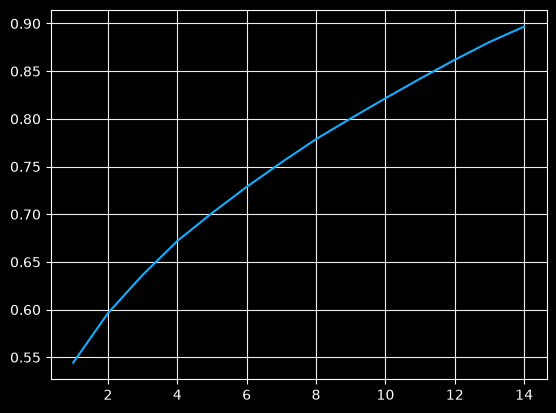

In [6]:
explain_variance = []
for i in range (1, 15):
  pca = PCA(n_components = i)
  pca.fit(df_encode_scale)
  explain_variance.append(sum(pca.explained_variance_ratio_))
plt.style.use('dark_background')
sns.lineplot(x = list(range(1,15)), y = explain_variance, color = "#12aeff")
plt.grid(color = "#eeeeee")

Ideal number of components here is 9 (explain ~ 80% of variance)

In [7]:
pca = PCA(n_components = 9)
pca.fit(df_encode_scale)
PCA_ds = pd.DataFrame(pca.transform(df_encode_scale), columns = (["col1","col2", "col3", "col4", "col5","col6", "col7", "col8", "col9"]))
PCA_ds.head()

,col1,col2,col3,col4,col5,col6,col7,col8,col9
0,-2.349187,0.733383,1.109463,1.672739,1.091228,2.220560,1.295546,-0.516223,0.056531
1,-2.371598,0.848509,1.207139,1.458819,1.167872,2.279911,1.242600,-0.542133,0.152973
2,-3.468187,1.356027,1.540361,0.792485,0.578860,1.100832,1.466131,-0.230960,0.349177
3,-3.490598,1.471154,1.638037,0.578565,0.655505,1.160183,1.413185,-0.256871,0.445619
4,-2.099013,-1.405306,0.986766,1.447832,2.378852,1.879144,-0.156015,0.156558,-1.115676


## c1. PCA scale

In [8]:
PCA_scale = PCA_ds.copy()

for c in PCA_ds.columns:
    m = PCA_ds[c].mean()
    sd = PCA_ds[c].std()
    PCA_scale[c] = (PCA_ds[c] - m)/sd
PCA_scale.head()

,col1,col2,col3,col4,col5,col6,col7,col8,col9
0,-0.435578,0.440742,0.758081,1.212595,0.872594,1.833845,1.107237,-0.451483,0.052497
1,-0.439733,0.509930,0.824822,1.057521,0.933882,1.882860,1.061986,-0.474144,0.142057
2,-0.643059,0.814933,1.052508,0.574485,0.462882,0.909120,1.253027,-0.201995,0.324261
3,-0.647214,0.884121,1.119249,0.419411,0.524171,0.958135,1.207776,-0.224656,0.413821
4,-0.389192,-0.844549,0.674244,1.049556,1.902236,1.551887,-0.133338,0.136924,-1.036064


## c2. PCA norm

In [9]:
PCA_norm = PCA_ds.copy()

for c in PCA_ds.columns:
    mn = PCA_ds[c].min()
    mx = PCA_ds[c].max()
    PCA_norm[c] = (PCA_ds[c] - mn)/(mx - mn)
PCA_norm.head()

,col1,col2,col3,col4,col5,col6,col7,col8,col9
0,0.052900,0.635642,0.797498,0.539272,0.758758,0.927486,0.595752,0.493713,0.504155
1,0.051897,0.648649,0.809727,0.517005,0.767149,0.933876,0.587219,0.490031,0.516119
2,0.002812,0.705989,0.851445,0.447648,0.702664,0.806926,0.623242,0.534256,0.540458
3,0.001809,0.718996,0.863673,0.425382,0.711055,0.813316,0.614710,0.530573,0.552422
4,0.064099,0.394012,0.782137,0.515862,0.899727,0.890726,0.361825,0.589331,0.358740


# 2. K-means

## a. Choose k

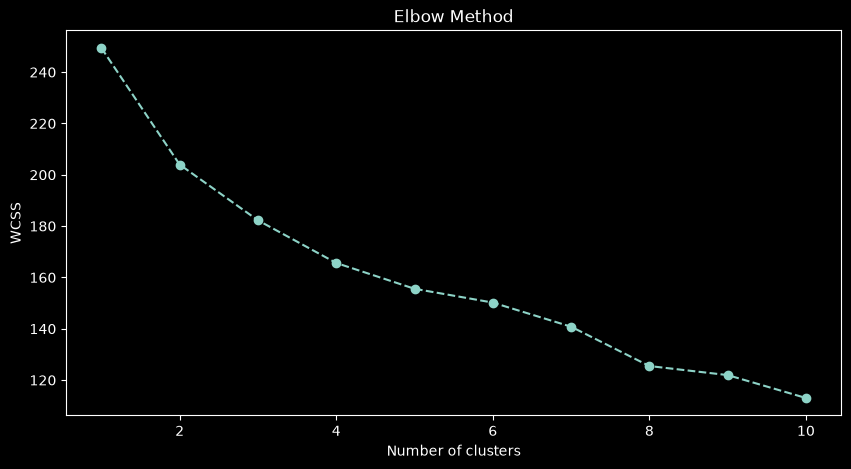

In [10]:
ss = []
max_clusters = 10
for i in range(1, max_clusters + 1):
    kmeans = KMeans(n_clusters = i, init = 'k-means++', random_state = 10)
    kmeans.fit(PCA_norm)
    ss.append(kmeans.inertia_)

# Plot the Elbow method
plt.figure(figsize = (10,5))
plt.plot(range(1, max_clusters + 1), ss, marker = 'o', linestyle = '--')
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

There is no optimal value for k, so segmentation churned customers is not necessary